In [ ]:
import pandas as pd
df = pd.read_csv("OIBSIP_Retail_Sales.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,T0001,2023-01-01 00:00:00.000000000,CUST472,Male,45,Clothing,1,100,100
1,T0002,2023-01-01 08:44:41.081081081,CUST377,Female,24,Electronics,1,100,100
2,T0003,2023-01-01 17:29:22.162162162,CUST378,Female,52,Electronics,2,50,100
3,T0004,2023-01-02 02:14:03.243243243,CUST389,Female,45,Clothing,4,30,120
4,T0005,2023-01-02 10:58:44.324324324,CUST070,Female,31,Beauty,2,500,1000


In [ ]:
df["Date"] = pd.to_datetime(df["Date"])
ref = df["Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(Recency=("Date", lambda x: (ref - x.max()).days), Frequency=("Transaction ID", "count"), Monetary=("Total Amount", "sum")).reset_index()
print(rfm.shape)
print(rfm.describe())

(434, 4)
          Recency   Frequency     Monetary
count  434.000000  434.000000   434.000000
mean   125.875576    2.304147  1025.241935
std     95.104237    1.217513   964.583517
min      1.000000    1.000000    25.000000
25%     44.250000    1.000000   300.000000
50%    109.000000    2.000000   750.000000
75%    190.000000    3.000000  1497.500000
max    360.000000    7.000000  6200.000000


Average purchase value: 444.96
Average purchase frequency per customer: 2.3
Average customer lifetime value: 1025.24


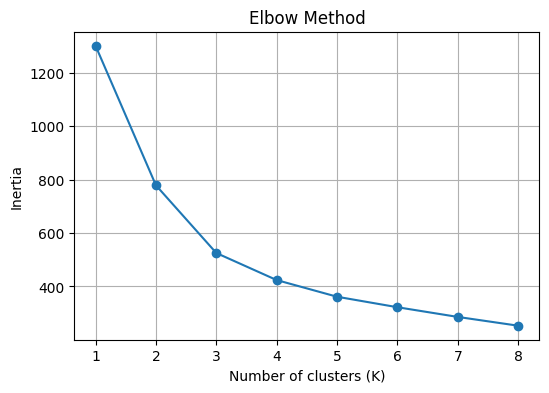

In [ ]:
print("Average purchase value:", round(df["Total Amount"].mean(), 2))
print("Average purchase frequency per customer:", round(rfm["Frequency"].mean(), 2))
print("Average customer lifetime value:", round(rfm["Monetary"].mean(), 2))
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
X = StandardScaler().fit_transform(rfm[["Recency", "Frequency", "Monetary"]])
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 9)]
plt.figure(figsize=(6, 4))
plt.plot(range(1, 9), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

## Feature Selection
I used RFM analysis with 3 behaviour features: Recency (days since last purchase), Frequency (number of purchases) and Monetary (total spend). Together they show how recently, how often and how much each customer buys. The values were standardised with StandardScaler so that no feature dominates because of its scale.

## Descriptive Statistics
- Average purchase value is 444.96.
- Average purchase frequency is 2.3 purchases per customer.
- Average customer lifetime value (total spend per customer) is 1,025.24.

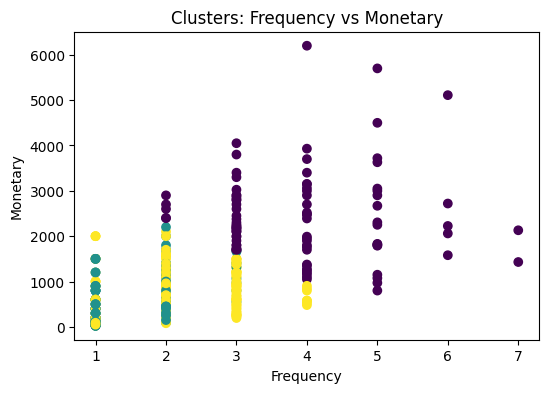

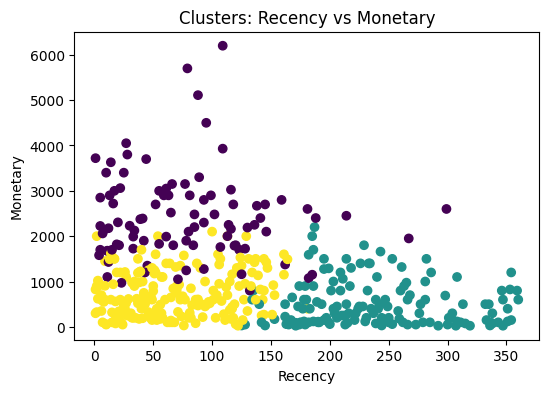

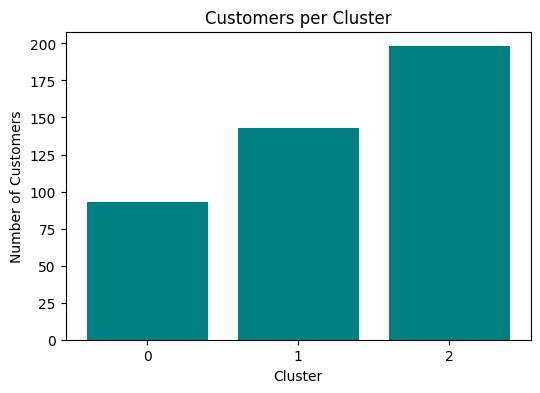

         Recency  Frequency  Monetary
Cluster                              
0           77.7        3.9    2415.1
1          237.4        1.4     514.9
2           68.0        2.2     741.0
Cluster
0     93
1    143
2    198
Name: count, dtype: int64


In [ ]:
rfm["Cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
plt.figure(figsize=(6, 4))
plt.scatter(rfm["Frequency"], rfm["Monetary"], c=rfm["Cluster"], cmap="viridis")
plt.title("Clusters: Frequency vs Monetary")
plt.xlabel("Frequency")
plt.ylabel("Monetary")
plt.show()
plt.figure(figsize=(6, 4))
plt.scatter(rfm["Recency"], rfm["Monetary"], c=rfm["Cluster"], cmap="viridis")
plt.title("Clusters: Recency vs Monetary")
plt.xlabel("Recency")
plt.ylabel("Monetary")
plt.show()
counts = rfm["Cluster"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(counts.index.astype(str), counts.values, color="teal")
plt.title("Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()
print(rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(1))
print(counts)

## Choosing the Number of Clusters
The Elbow Method plot shows that the drop in inertia slows down clearly after K=3, so K=3 was chosen for K-Means.

## Cluster Profiles
| Cluster | Customers | Avg Recency (days) | Avg Frequency | Avg Spend | Customer Type |
|---|---|---|---|---|---|
| 0 | 93 | 77.7 | 3.9 | 2,415 | Loyal high spenders |
| 1 | 143 | 237.4 | 1.4 | 515 | Inactive, at-risk customers |
| 2 | 198 | 68.0 | 2.2 | 741 | Recent average customers |

## Insights - Marketing Action for Each Segment
- **Cluster 0 (21% of customers):** they buy often and spend the most. Reward them with a loyalty program, early access to new products and premium bundles. Heavy discounts are not needed.
- **Cluster 1 (33%):** they have not bought for about 8 months and spend little. Run a win-back campaign with a reminder email and a limited-time discount.
- **Cluster 2 (46%):** the biggest group, they bought recently but spend moderately. Use cross-sell and bundle offers to move them towards Cluster 0.